In [1]:
import scib
from scib_metrics.benchmark import Benchmarker

import os
import warnings
import scanpy as sc
import torch
import scarches as sca
from scarches.dataset.trvae.data_handling import remove_sparsity
import matplotlib.pyplot as plt
import numpy as np
import diopy
import omicverse as ov
import scvi
from scvi.model import SCVI
import scanorama

os.chdir('E:\Data\LXW\integration_method')
warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.simplefilter(action='ignore', category=UserWarning)

d:\soft\anaconda\envs\scarches\lib\site-packages\umap\__init__.py:9: ImportWarning: Tensorflow not installed; ParametricUMAP will be unavailable
  warn(
d:\soft\anaconda\envs\scarches\lib\site-packages\datatree\__init__.py:10: DeprecationWarning: The repository `xarray-contrib/datatree` has been archived! It is no longer maintained as of October 2024. Datatree functionality has been migrated upstream to `pydata/xarray`, so please use `xarray.DataTree` instead. To help you migrate a guide can be found by following https://github.com/pydata/xarray/discussions/9680
  warnings.warn(
d:\soft\anaconda\envs\scarches\lib\site-packages\xarray_schema\__init__.py:1: DeprecationWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html
  from pkg_resources import DistributionNotFound, get_distribution
d:\soft\anaconda\envs\scarches\lib\site-packages\pkg_resources\__init__.py:3154: DeprecationWarning: Deprecated call to `pkg_resources.declare_namespa


   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__  )  __/ 
\____/_/ /_/ /_/_/\___/ |___/\___/_/  /____/\___/                                              

Version: 1.6.8, Tutorials: https://omicverse.readthedocs.io/


In [2]:
adata_h = diopy.input.read_h5("E:\Data\LXW\integration_method\scRNA_human.h5",assay_name= 'RNA3')
adata_m = diopy.input.read_h5("E:\Data\LXW\integration_method\scRNA_monkey.h5",assay_name= 'RNA3')
adata_r = diopy.input.read_h5("E:\Data\LXW\integration_method\scRNA_rat.h5",assay_name= 'RNA3')
adata_g = diopy.input.read_h5("E:\Data\LXW\integration_method\scRNA_goat.h5",assay_name= 'RNA3')
adata_h.obs['sp'] = 'hsa'
adata_m.obs['sp'] = 'mcc'
adata_r.obs['sp'] = 'rno'
adata_g.obs['sp'] = 'chx'

adata=sc.concat([adata_h,adata_m,adata_r,adata_g],merge='unique')
adata1 = adata.copy()

In [23]:
import os
import pandas as pd
import numpy as np

# 定义文件夹路径和 AnnData 对象
file_path = r"E:/Data/LXW/integration_method/files"

# 遍历文件夹中的 UMAP 文件并添加到 AnnData
for file in os.listdir(file_path):
    if file.endswith(".csv"):
        print(file)
        file_name = os.path.splitext(file)[0]  # 去掉文件扩展名
        full_path = os.path.join(file_path, file)

        # 加载 UMAP 坐标
        umap_coords = pd.read_csv(full_path, index_col=0)  # 假设第 0 列是细胞名称
        
        # 检查 umap_coords 的索引和 adata1.obs_names 是否一致
        print("CSV 文件索引:", umap_coords.index[:5])  # 输出前5个索引
        print("AnnData obs_names:", adata1.obs_names[:5])  # 输出 AnnData 对象前5个索引

        # 确保细胞名称一致
        common_cells = umap_coords.index.intersection(adata1.obs_names)  # 找到共同的细胞
        if len(common_cells) == 0:
            raise ValueError(f"No common cells found between {file_name} and adata1.obs_names")

        # 对齐细胞名称
        umap_coords = umap_coords.loc[common_cells]
        adata1 = adata1[common_cells].copy()  # 确保 adata1 也只保留共同的细胞

        # 添加到 AnnData 的 obsm 中
        adata1.obsm[f"X_{file_name}"] = umap_coords.values

umap_anchors_cca.csv
CSV 文件索引: Index(['Macaque_MOD_AAACCCAAGACATACA-1', 'Macaque_MOD_AAACCCAAGTACGAGC-1',
       'Macaque_MOD_AAACCCAAGTCCGCGT-1', 'Macaque_MOD_AAACCCACAAATGATG-1',
       'Macaque_MOD_AAACCCACAACAAGTA-1'],
      dtype='object')
AnnData obs_names: Index(['Human_180G YA2023204-1_scRNA_ReportCellRanger11OS-2024-6-6_AAACCCAAGAATCGTA-1',
       'Human_180G YA2023204-1_scRNA_ReportCellRanger11OS-2024-6-6_AAACCCAAGAGGTATT-1',
       'Human_180G YA2023204-1_scRNA_ReportCellRanger11OS-2024-6-6_AAACCCAAGCCATGCC-1',
       'Human_180G YA2023204-1_scRNA_ReportCellRanger11OS-2024-6-6_AAACCCAAGGTTTACC-1',
       'Human_180G YA2023204-1_scRNA_ReportCellRanger11OS-2024-6-6_AAACCCAAGTCAGCCC-1'],
      dtype='object', name='index')
umap_cca.csv
CSV 文件索引: Index(['Macaque_MOD_AAACCCAAGACATACA-1', 'Macaque_MOD_AAACCCAAGTACGAGC-1',
       'Macaque_MOD_AAACCCAAGTCCGCGT-1', 'Macaque_MOD_AAACCCACAAATGATG-1',
       'Macaque_MOD_AAACCCACAACAAGTA-1'],
      dtype='object')
AnnData obs_names: Ind

Plotting UMAP for: X_umap_latent
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_latent.pdf
Plotting UMAP for: X_umap_cca
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_cca.pdf
Plotting UMAP for: X_umap_anchors_cca
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_anchors_cca.pdf
Plotting UMAP for: X_umap_scvi
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_scvi.pdf
Plotting UMAP for: X_umap_harmony
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_harmony.pdf
Plotting UMAP for: X_umap_liger
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_liger.pdf
Plotting UMAP for: X_umap_mnn
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_mnn.pdf
Plotting UMAP for: X_umap_scanorama
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_scanorama.pdf
Plotting UMAP for: X_umap_scanvi
Saved plot to: E:/Data/LXW/integration_method/figures_new/X_umap_scanvi.pdf


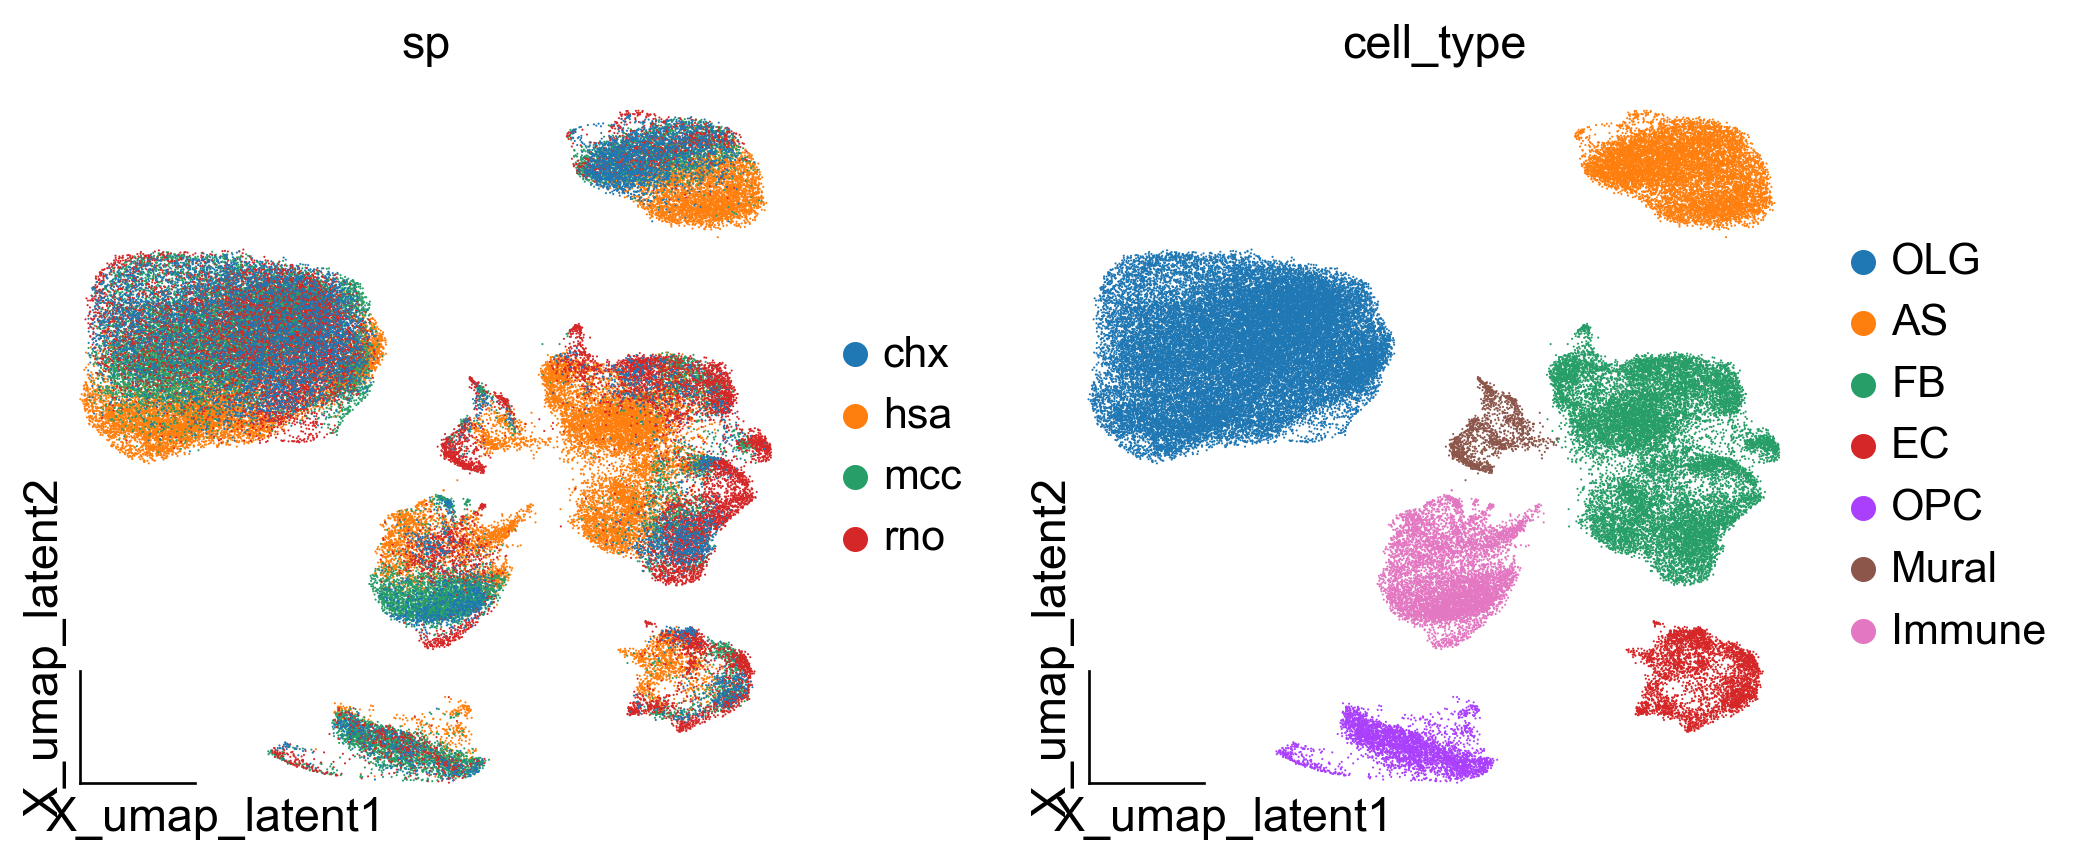

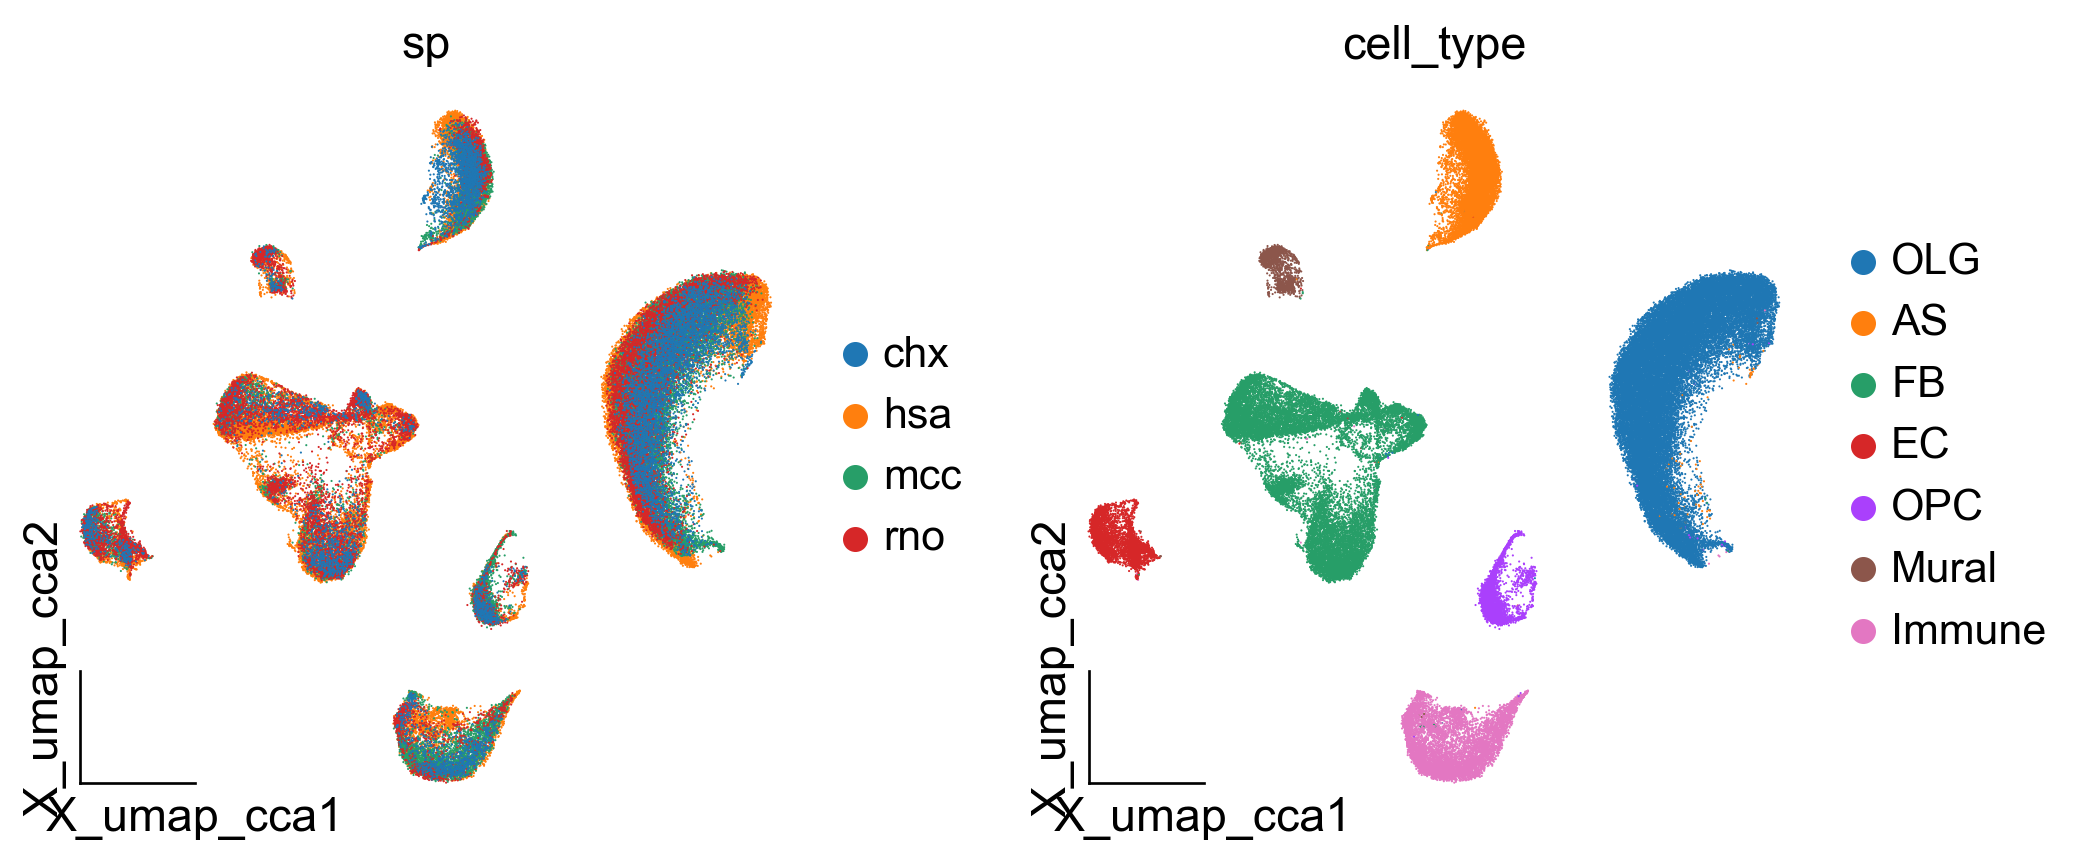

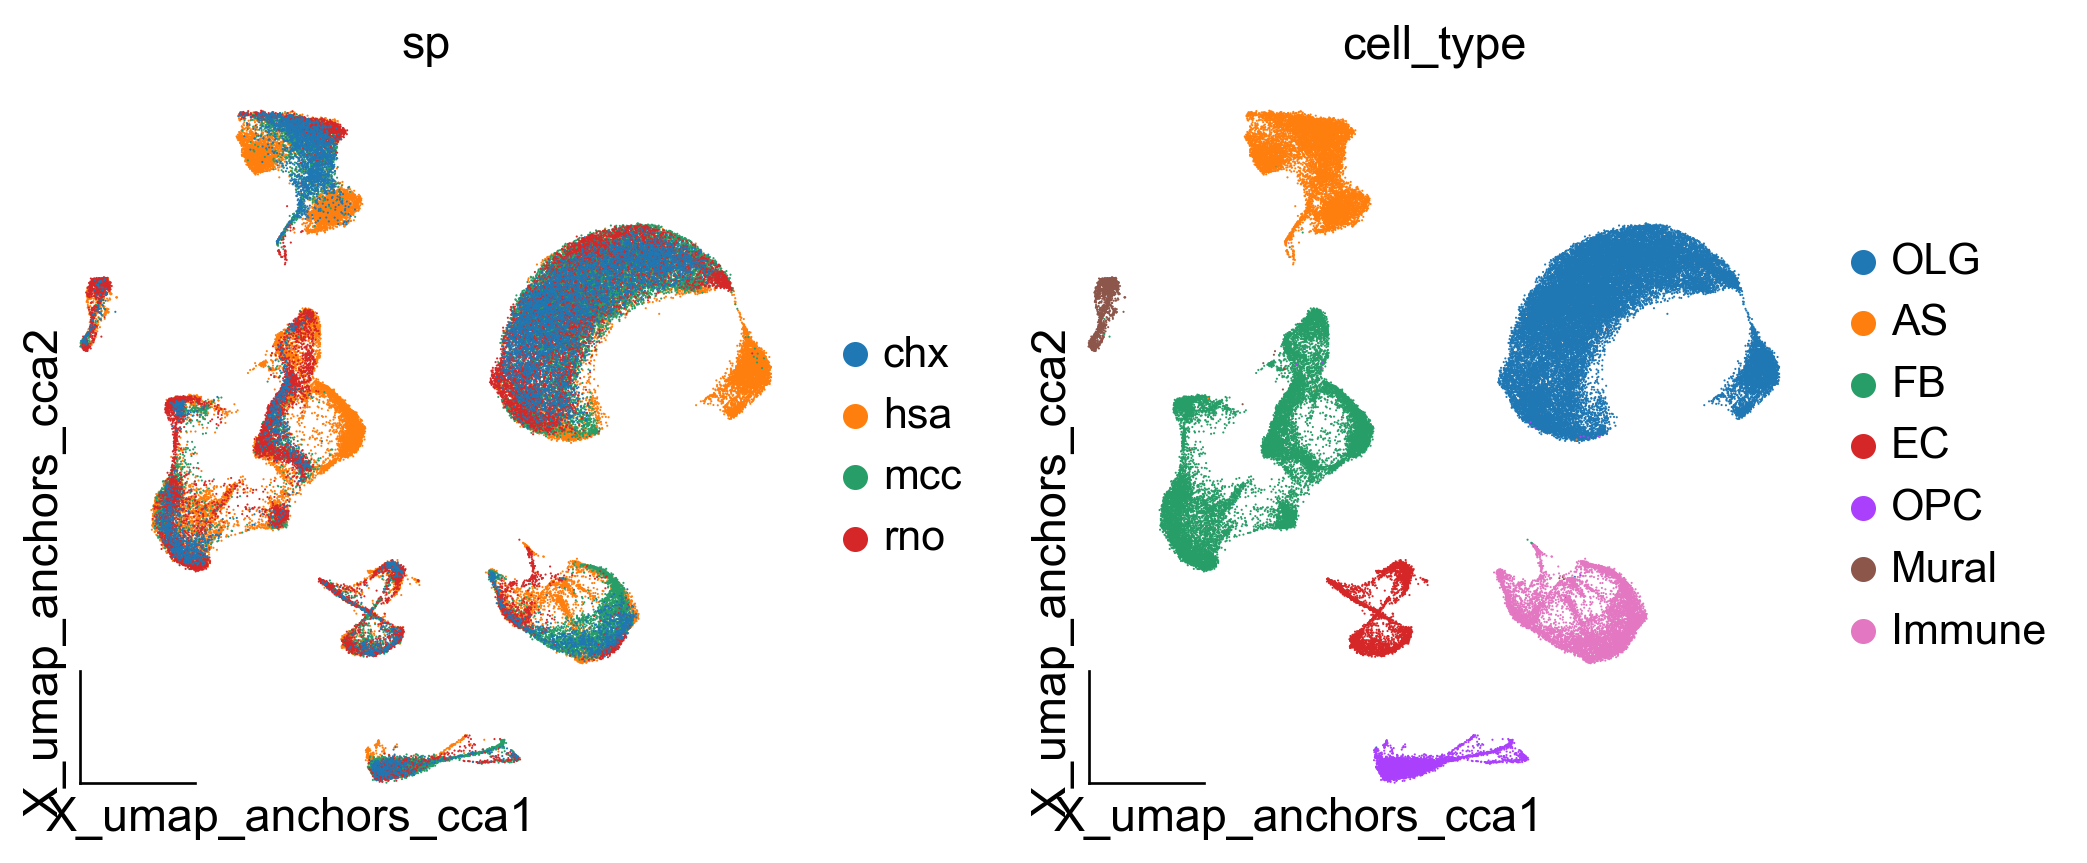

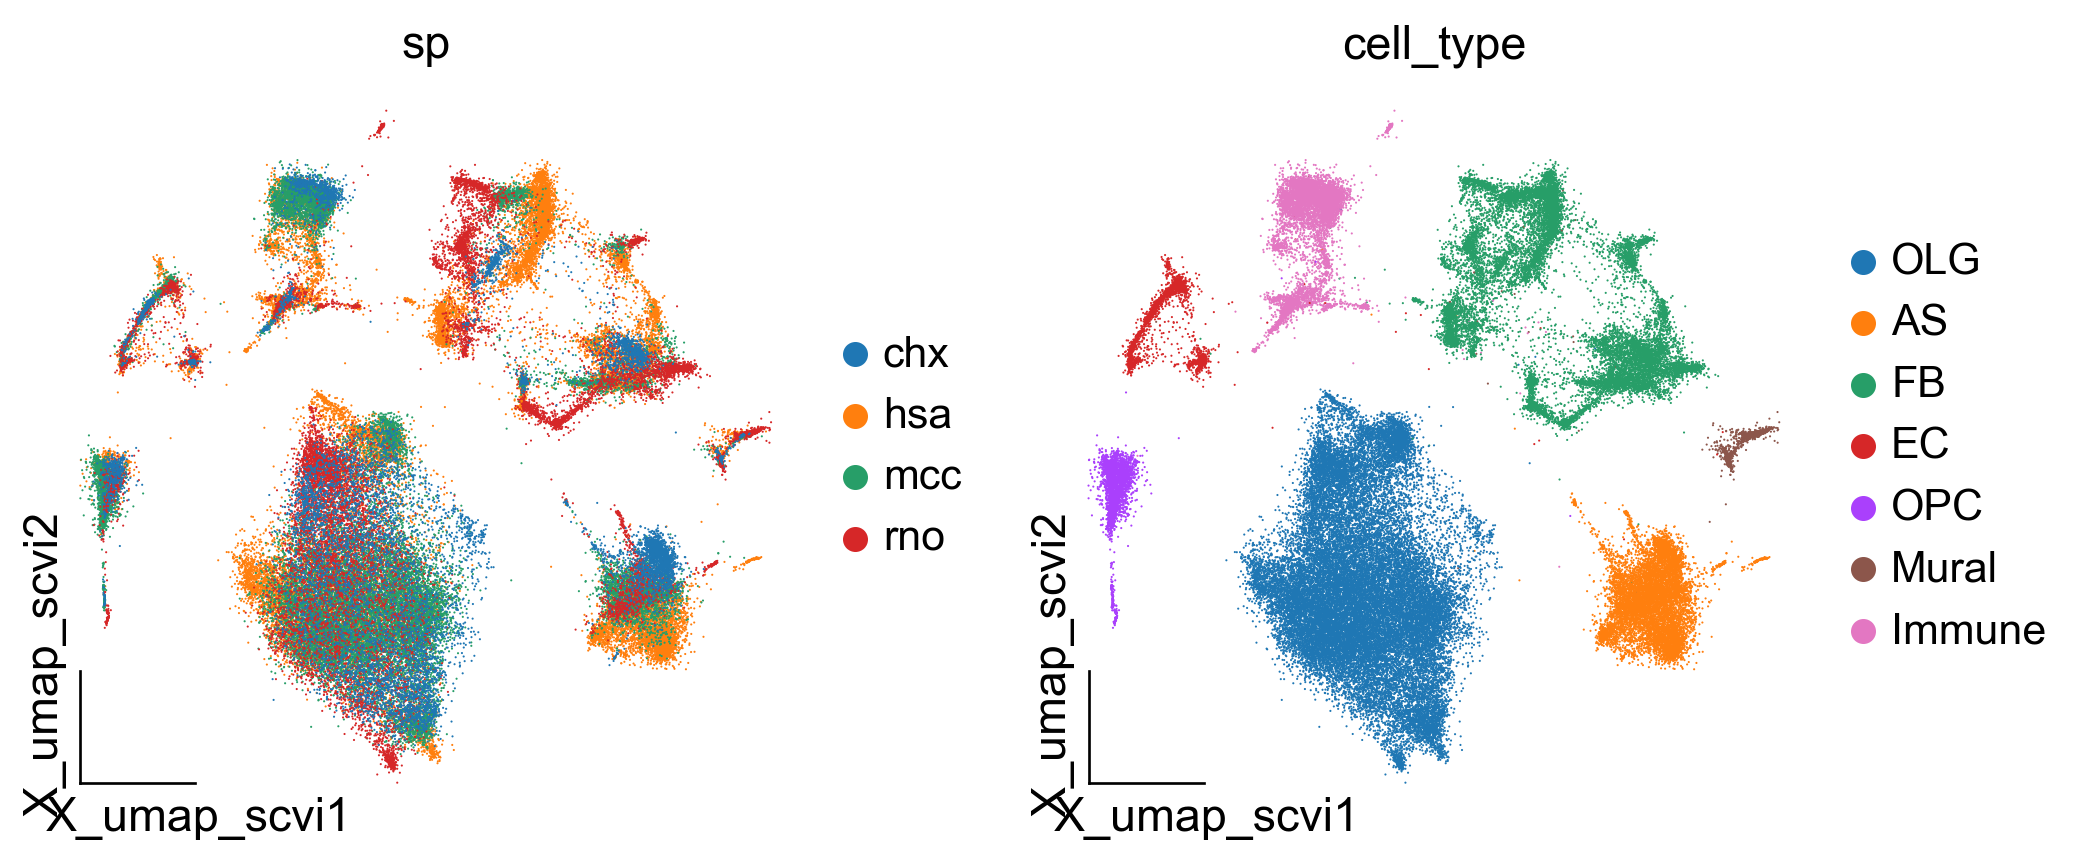

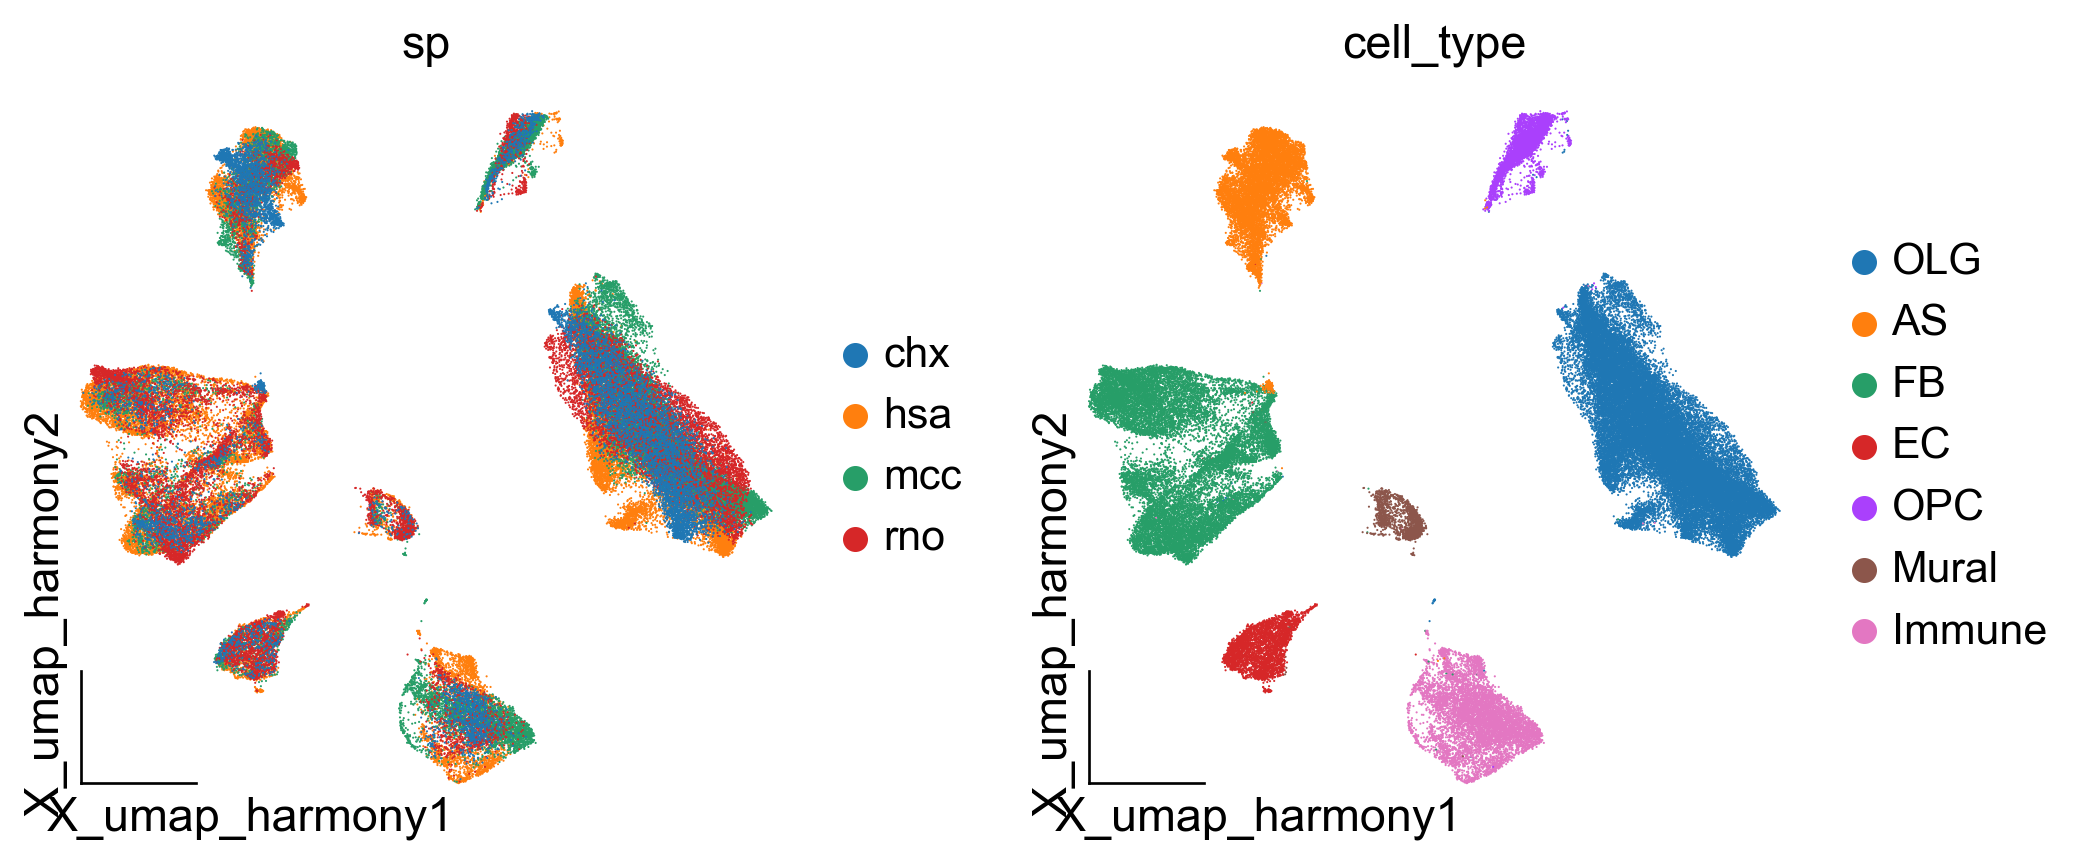

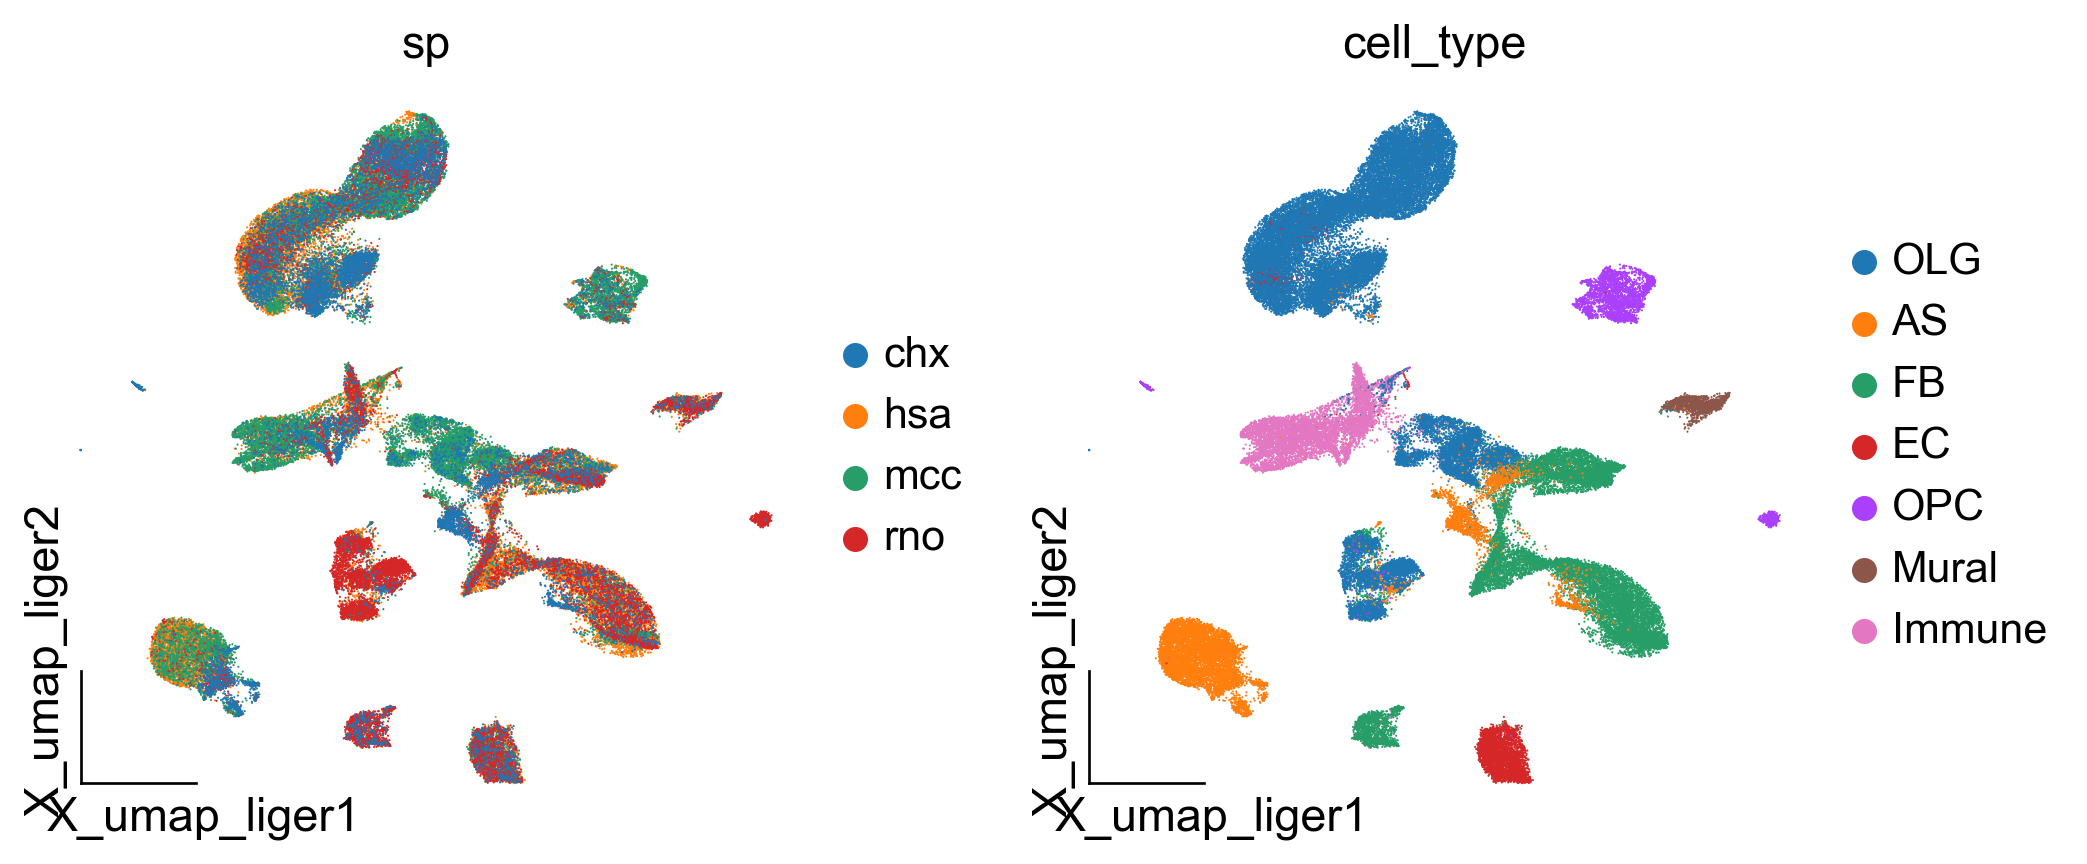

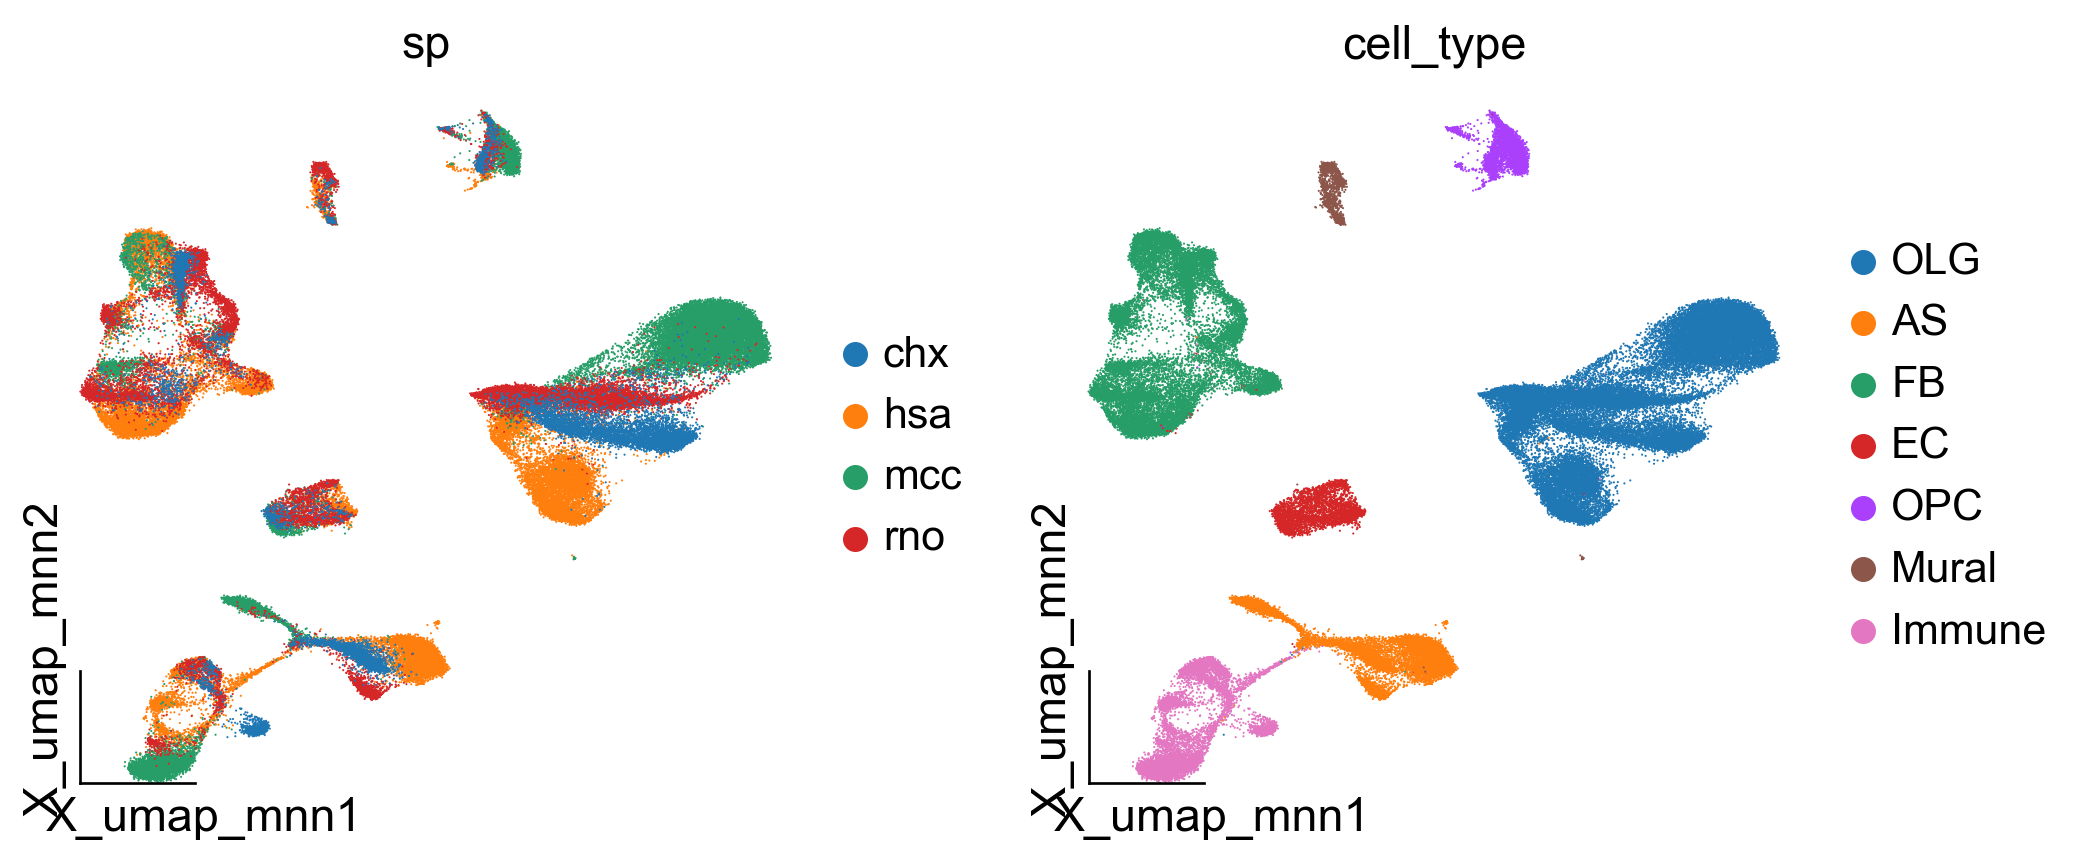

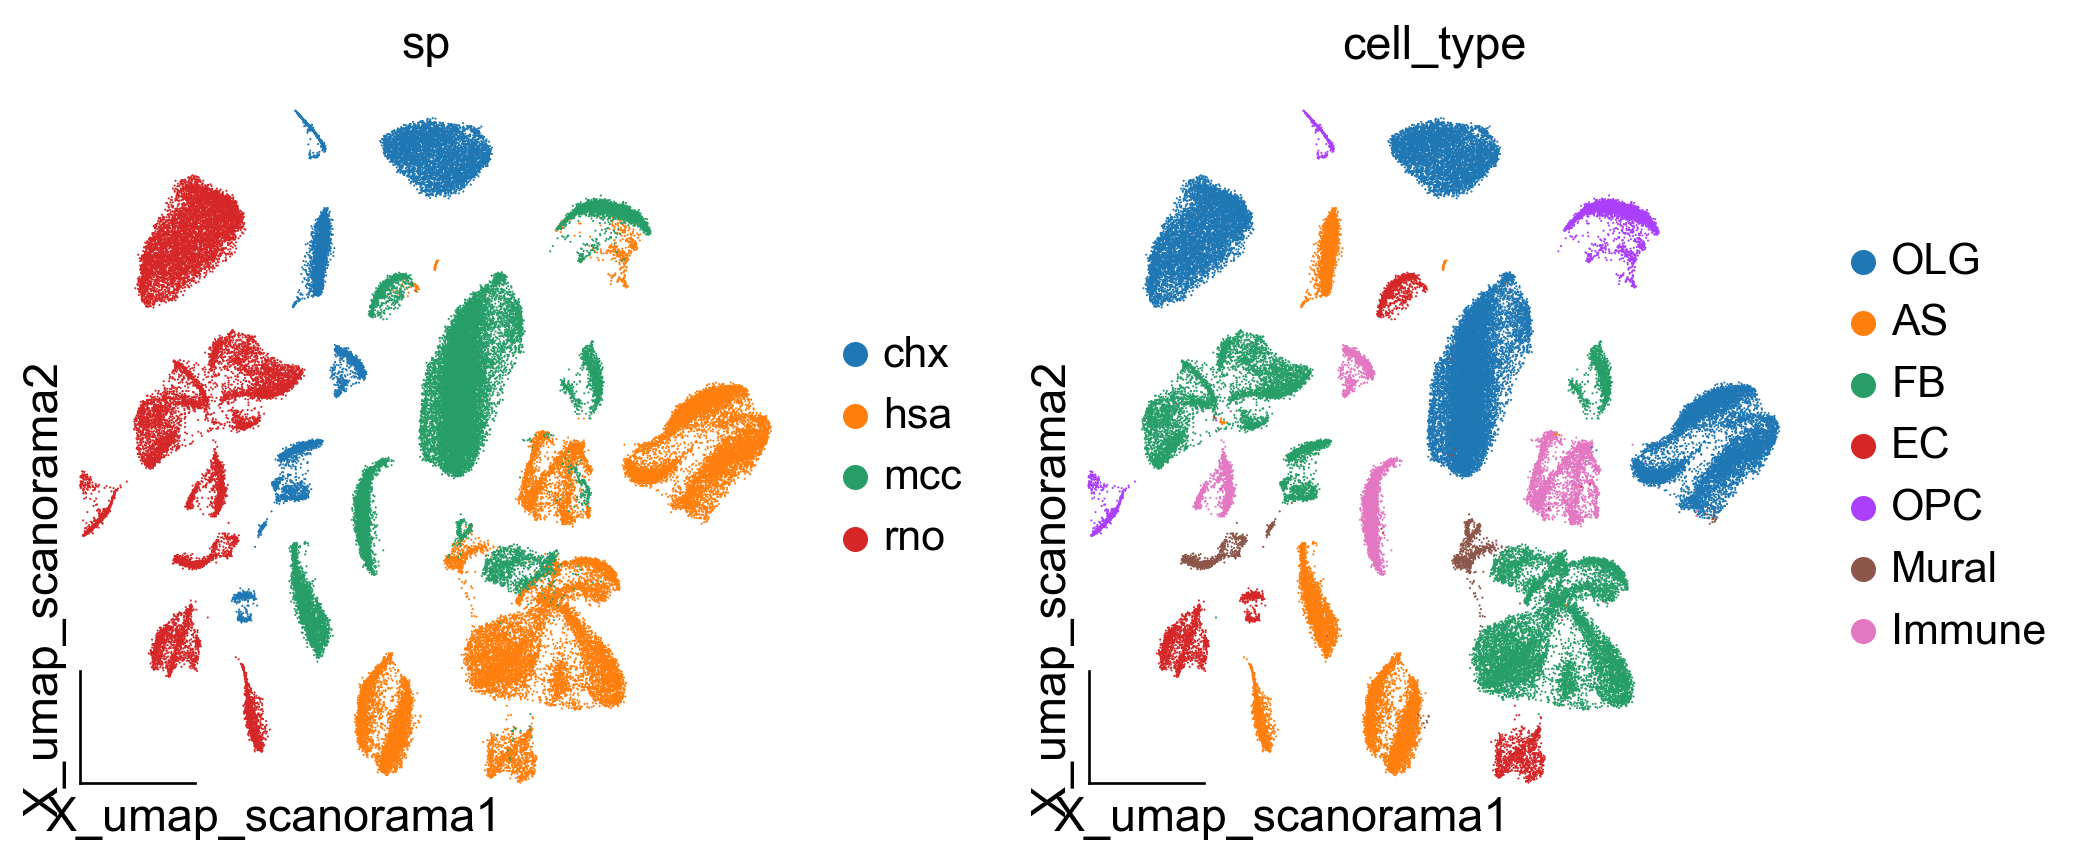

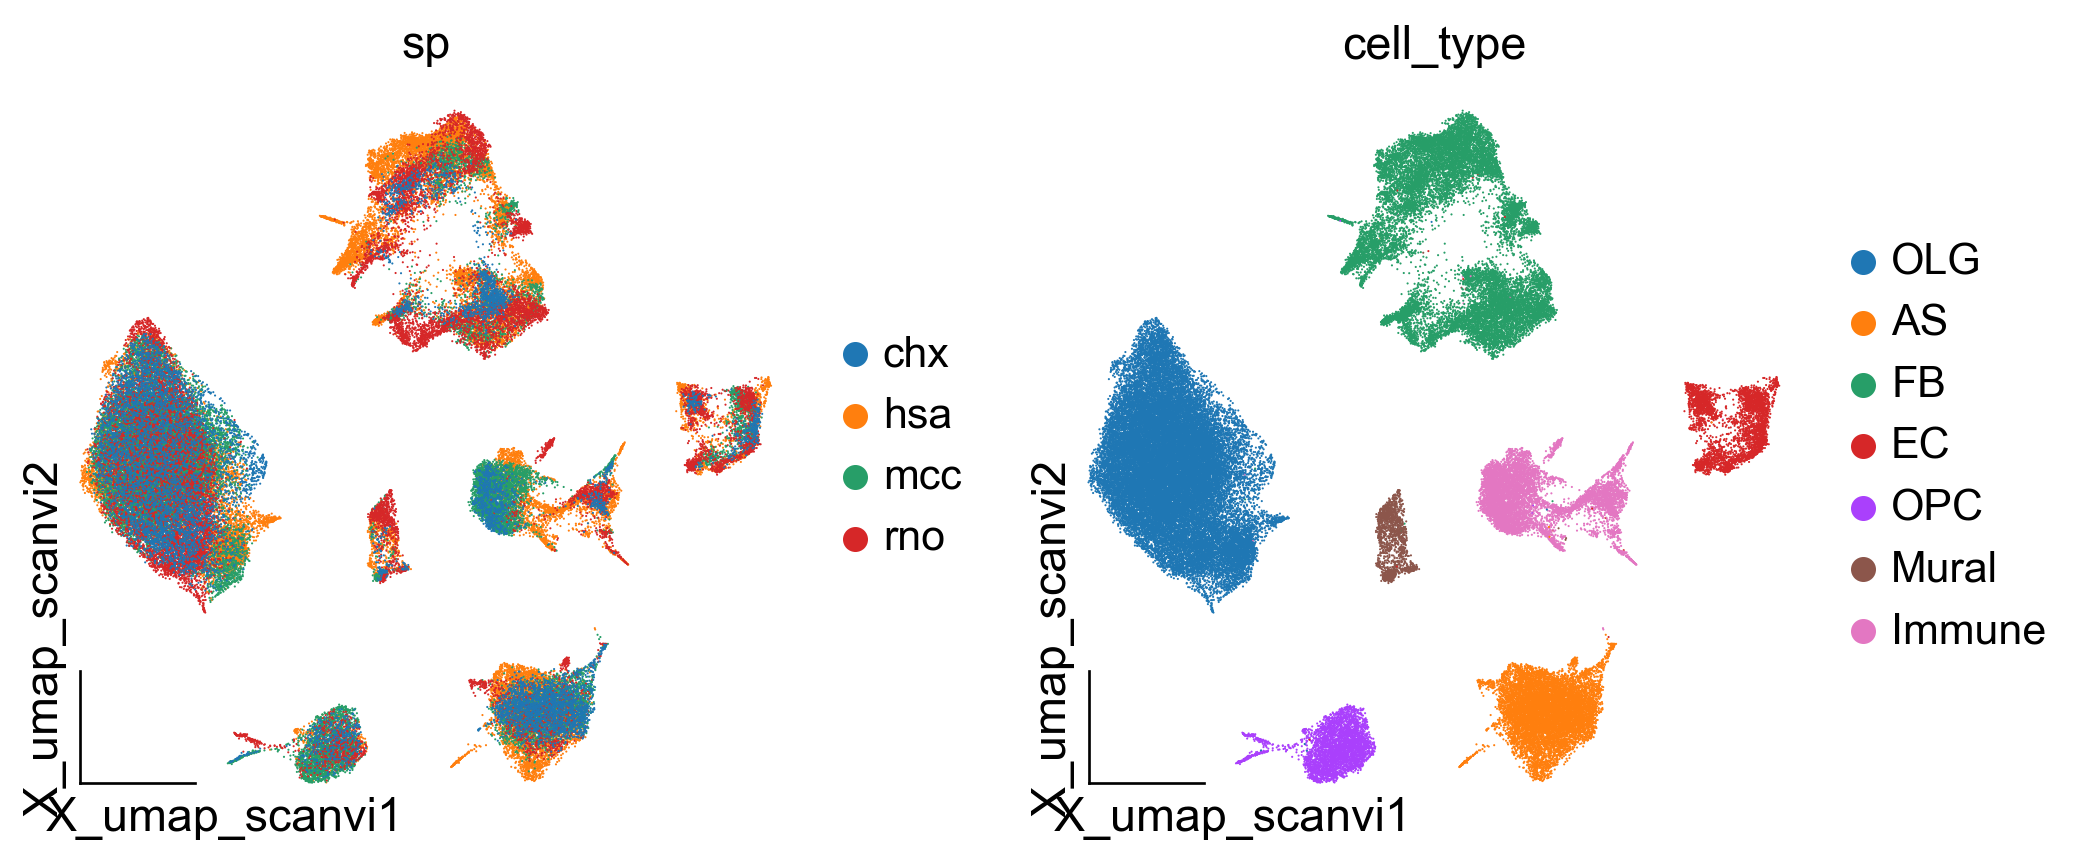

In [26]:
# 定义要绘图的坐标名称
umap_coordinates = [
    'X_umap_latent',
    'X_umap_cca',
    'X_umap_anchors_cca',
    'X_umap_scvi',
    'X_umap_harmony',
    'X_umap_liger',
    'X_umap_mnn',
    'X_umap_scanorama',
    'X_umap_scanvi'
]

# 遍历每个坐标名称并绘图
for umap_name in umap_coordinates:
    print(f"Plotting UMAP for: {umap_name}")  # 输出当前绘制的坐标名称
    
    ov.utils.embedding(
        adata1,                        # AnnData 对象
        basis=umap_name,              # 使用指定的 UMAP 坐标
        frameon='small',              # 设置框架样式
        color=['sp', 'cell_type'],    # 设置用于着色的列
        show=False                    # 不显示图形，方便保存
    )
    
    # 保存图像
    save_path = f"E:/Data/LXW/integration_method/figures_new/{umap_name}.pdf"
    plt.savefig(save_path, format='pdf')  # 保存为 PDF 格式
    print(f"Saved plot to: {save_path}")


In [15]:
adata1.obsm

AxisArrays with keys: X_latent, X_umap_latent, X_umap_anchors_cca, X_umap_cca, X_umap_harmony, X_umap_liger, X_umap_mnn, X_umap_rpca, X_umap_scanorama, X_umap_scanvi, X_umap_scvi

In [27]:
bm = Benchmarker(
    adata1,
    batch_key="orig.ident",
    label_key="cell_type",
    embedding_obsm_keys=['X_umap_latent',
    'X_umap_cca',
    'X_umap_anchors_cca',
    'X_umap_scvi',
    'X_umap_harmony',
    'X_umap_liger',
    'X_umap_mnn',
    'X_umap_scanorama',
    'X_umap_scanvi'],
    n_jobs=8,
)
bm.benchmark()

Embeddings: 100%|██████████| 9/9 [12:21<00:00, 82.42s/it]


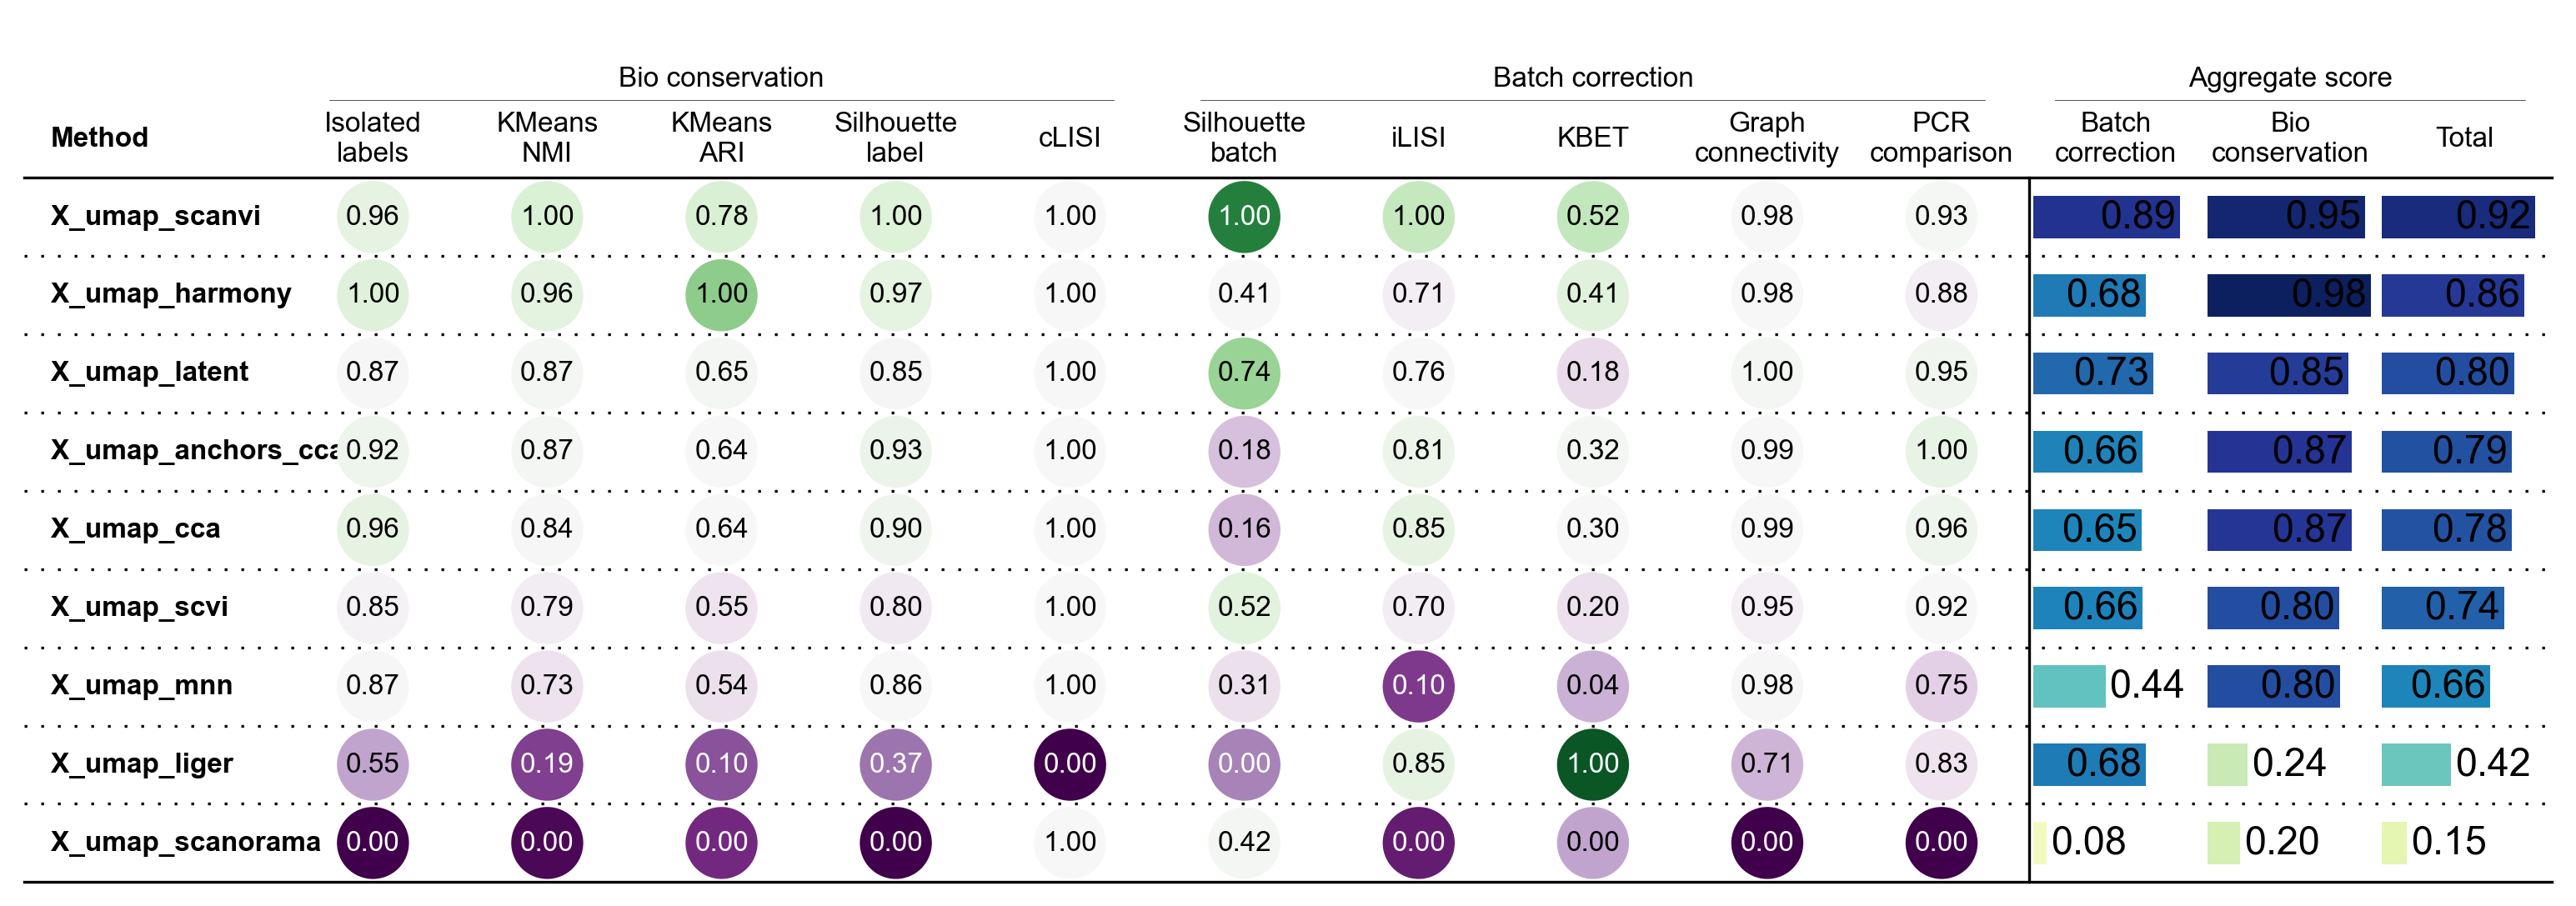

Fig saved as scbi_assessment.pdf in E:/Data/LXW/integration_method/figures


In [28]:
bm.plot_results_table(min_max_scale=True, save_dir = "E:/Data/LXW/integration_method/figures_new")

print('Fig saved as scbi_assessment.pdf in E:/Data/LXW/integration_method/figures')